# Curso: Data Mining — Semana 9
## <font color=green>Laboratorio: Selección de atributos</font>

**Docente:** Soledad Espezúa Llerena

En este laboratorio veremos tres formas de seleccionar atributos:

1. **Filter:** evalúa los atributos sin depender del modelo predictivo final.
2. **Wrapper:** prueba subconjuntos utilizando un modelo como evaluador.
3. **Embedded:** la relevancia de los atributos se obtiene durante el entrenamiento del modelo.

<font color=red>**Importante:** no siempre existe una variable objetivo. En ese caso no debemos inventarla. La selección puede comenzar revisando atributos constantes, redundantes o poco informativos.</font>


## <font color=green>1. Datos del ejemplo</font>

Usaremos el conjunto **Breast Cancer Wisconsin (Diagnostic)**.

- Cada fila representa una observación.
- Las columnas numéricas son atributos.
- `diagnostico` será la variable objetivo del ejemplo.

**Fuente:** Wolberg, W., Mangasarian, O., Street, N., & Street, W. (1993). *Breast Cancer Wisconsin (Diagnostic)*. UCI Machine Learning Repository.



## <font color=green>2. Librerías</font>


In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.feature_selection import (
    SelectKBest,
    chi2,
    f_classif,
    RFE,
    SequentialFeatureSelector
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

pd.set_option("display.precision", 3)
sns.set_theme(style="ticks")
np.set_printoptions(precision=3, suppress=True)


### <font color=blue>Función auxiliar para comparar selecciones</font>

Cuando dos métodos seleccionan el mismo número `k` de atributos, podemos medir cuánto coinciden:
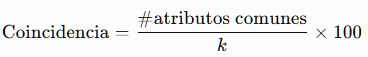

Esto nos permitirá **cuantificar** cuánto cambia la selección, en lugar de limitarnos a decir que "se ve diferente".


In [29]:
def comparar_selecciones(lista_a, lista_b):
    # Compara dos listas de atributos seleccionados.
    set_a = set(lista_a)
    set_b = set(lista_b)

    comunes = sorted(set_a.intersection(set_b))
    k = min(len(set_a), len(set_b))

    porcentaje = (len(comunes) / k * 100) if k > 0 else np.nan

    return {
        "atributos_comunes": comunes,
        "n_comunes": len(comunes),
        "k_comparado": k,
        "porcentaje_coincidencia": round(porcentaje, 2)
    }


# <font color=green>PARTE I. Caso guiado: Breast Cancer Wisconsin</font>

Usaremos el conjunto **Breast Cancer Wisconsin (Diagnostic)** para revisar los tres enfoques.

- Cada fila representa una observación.
- Las columnas numéricas corresponden a atributos.
- `diagnostico` se utilizará como variable de interés únicamente para que los métodos supervisados puedan evaluar la relevancia de los atributos.

<font color=red>**Importante:** en esta sesión utilizamos modelos únicamente como herramientas de evaluación dentro de Wrapper y Embedded. La construcción y evaluación de modelos predictivos corresponde al curso de Machine Learning.</font>


**Fuente:** Wolberg, W., Mangasarian, O., Street, N., & Street, W. (1993). *Breast Cancer Wisconsin (Diagnostic)*. UCI Machine Learning Repository.


In [3]:
filename = "Breast_data.xls"

data = pd.read_excel(filename, index_col=0)

print("Dimensiones:", data.shape)
data.head()

Dimensiones: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnostico
0,17.99,10.38,122.80,1001.0,0.118,0.278,0.300,0.147,0.242,0.079,...,17.33,184.60,2019.0,0.162,0.666,0.712,0.265,0.460,0.119,0
1,20.57,17.77,132.90,1326.0,0.085,0.079,0.087,0.070,0.181,0.057,...,23.41,158.80,1956.0,0.124,0.187,0.242,0.186,0.275,0.089,0
2,19.69,21.25,130.00,1203.0,0.110,0.160,0.197,0.128,0.207,0.060,...,25.53,152.50,1709.0,0.144,0.424,0.450,0.243,0.361,0.088,0
3,11.42,20.38,77.58,386.1,0.142,0.284,0.241,0.105,0.260,0.097,...,26.50,98.87,567.7,0.210,0.866,0.687,0.258,0.664,0.173,0
4,20.29,14.34,135.10,1297.0,0.100,0.133,0.198,0.104,0.181,0.059,...,16.67,152.20,1575.0,0.137,0.205,0.400,0.163,0.236,0.077,0


## <font color=green>3. Separamos atributos y variable de interés</font>


In [4]:
X = data.drop(columns=["diagnostico"])
y = data["diagnostico"]

print("Número de observaciones:", X.shape[0])
print("Número de atributos:", X.shape[1])
print("\nValores de la variable de interés:")
display(y.value_counts())

Número de observaciones: 569
Número de atributos: 30

Valores de la variable de interés:


diagnostico
1    357
0    212
Name: count, dtype: int64

# <font color=green>4. Filter: SelectKBest + ANOVA (`f_classif`)</font>

Los métodos **Filter** evalúan los atributos de manera individual mediante un criterio estadístico o de información.

En este ejemplo utilizaremos `f_classif`, que calcula un estadístico ANOVA para cada atributo respecto de la variable de interés.

Seleccionaremos los **5 atributos con mayor puntuación**.


In [5]:
# 1. Creamos el selector
selector_filter = SelectKBest(score_func=f_classif, k=5)

# 2. Evaluamos los atributos respecto de y
selector_filter.fit(X, y)

# 3. Construimos una tabla interpretable
# get_support() devuelve True para los atributos seleccionados.
tabla_filter = pd.DataFrame({
    "atributo": X.columns,
    "score": selector_filter.scores_,
    "seleccionado": selector_filter.get_support()
}).sort_values("score", ascending=False)

display(tabla_filter.head(10))

,atributo,score,seleccionado
27,worst concave points,964.385,True
22,worst perimeter,897.944,True
7,mean concave points,861.676,True
20,worst radius,860.782,True
2,mean perimeter,697.235,True
23,worst area,661.600,False
0,mean radius,646.981,False
3,mean area,573.061,False
6,mean concavity,533.793,False
26,worst concavity,436.692,False


In [6]:
# Atributos seleccionados
atributos_filter = X.columns[selector_filter.get_support()].tolist()

print("Atributos seleccionados por Filter:")
for atributo in atributos_filter:
    print("-", atributo)

# Matriz reducida
X_filter = X[atributos_filter].copy()
print("\nDimensión original:", X.shape)
print("Dimensión reducida:", X_filter.shape)

Atributos seleccionados por Filter:
- mean perimeter
- mean concave points
- worst radius
- worst perimeter
- worst concave points

Dimensión original: (569, 30)
Dimensión reducida: (569, 5)


### <font color=blue>Visualizamos el ranking</font>


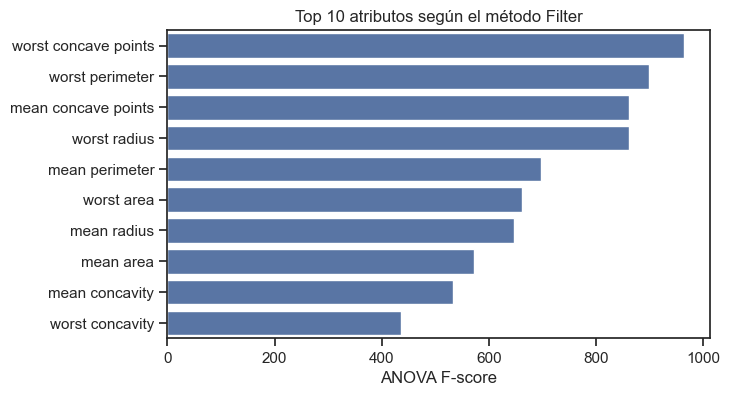

In [7]:
# Visualizamos los 10 atributos con mayor score
top_filter = tabla_filter.head(10).sort_values("score", ascending=False)
plt.figure(figsize=(7,4))
ax = sns.barplot(
    data=top_filter,
    x="score",
    y="atributo"
)
plt.title("Top 10 atributos según el método Filter")
plt.xlabel("ANOVA F-score")
plt.ylabel("")
plt.show()

### <font color=blue>Interpretación</font>

Observe que `SelectKBest` no decide si un atributo es "bueno" en términos absolutos.  
Lo que hace es **ordenar los atributos según el criterio elegido** y conservar los `k` primeros.

<font color=red> ANOVA analiza cada atributo por separado. Puede no detectar interacciones entre variables.</font>


<font color=red>**Recuerda:** un método Filter responde a una pregunta del tipo: "¿qué tan relacionado está cada atributo con la variable de interés según este criterio?". Si cambiamos el criterio, la selección también puede cambiar.</font>


# <font color=green>5. Wrapper: Recursive Feature Elimination (RFE)</font>

Un método **Wrapper** utiliza un modelo como evaluador.

RFE realiza el siguiente proceso:

1. entrena el modelo con los atributos disponibles;
2. identifica los menos importantes;
3. elimina atributos;
4. vuelve a entrenar;
5. repite hasta llegar al número solicitado.

Utilizaremos `LogisticRegression` únicamente como **estimador de apoyo**.


### <font color=blue>Antes de aplicar el modelo: estandarizamos</font>

La Regresión Logística es sensible a la escala de las variables, por lo que usaremos `StandardScaler`.

La estandarización transforma cada atributo aproximadamente a:

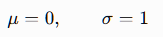


In [8]:
# Algunos modelos son sensibles a la escala.
# Por ello estandarizamos X antes de usar Regresión Logística.
estandarizador = StandardScaler()

# fit_transform():
# 1. calcula media y desviación de cada atributo;
# 2. transforma los datos usando esos valores.
#
# Reconstruimos un DataFrame para conservar los nombres de columnas.
X_std = pd.DataFrame(
    estandarizador.fit_transform(X),
    columns=X.columns,
    index=X.index
)

display(X_std.head())

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,1.097,-2.073,1.270,0.984,1.568,3.284,2.653,2.532,2.218,2.256,...,1.887,-1.359,2.304,2.001,1.308,2.617,2.110,2.296,2.751,1.937
1,1.830,-0.354,1.686,1.909,-0.827,-0.487,-0.024,0.548,0.001,-0.869,...,1.806,-0.369,1.535,1.890,-0.376,-0.430,-0.147,1.087,-0.244,0.281
2,1.580,0.456,1.567,1.559,0.942,1.053,1.363,2.037,0.940,-0.398,...,1.512,-0.024,1.347,1.456,0.527,1.083,0.855,1.955,1.152,0.201
3,-0.769,0.254,-0.593,-0.764,3.284,3.403,1.916,1.452,2.867,4.911,...,-0.281,0.134,-0.250,-0.550,3.394,3.893,1.990,2.176,6.046,4.935
4,1.750,-1.152,1.777,1.826,0.280,0.539,1.371,1.428,-0.010,-0.562,...,1.299,-1.467,1.339,1.221,0.221,-0.313,0.613,0.729,-0.868,-0.397


In [9]:
# Modelo que RFE utilizará como evaluador
modelo_wrapper = LogisticRegression(
    max_iter=2000,      # máximo número de iteraciones para lograr convergencia
    solver="liblinear", # algoritmo de optimización apropiado para este ejemplo
    random_state=1      # permite reproducir los resultados
)

# RFE = Recursive Feature Elimination.
# Comienza con todos los atributos y va eliminando los menos relevantes.
selector_rfe = RFE(
    estimator=modelo_wrapper,   # modelo que evaluará la importancia
    n_features_to_select=5,     # número final de atributos que queremos conservar
    step=1                      # elimina 1 atributo en cada iteración
)

# RFE ajusta repetidamente el modelo hasta quedarse con 5 atributos.
selector_rfe.fit(X_std, y)

# get_support() devuelve True para los atributos seleccionados.
atributos_rfe = X.columns[selector_rfe.get_support()].tolist()

print("Atributos seleccionados por RFE:")
for atributo in atributos_rfe:
    print("-", atributo)

Atributos seleccionados por RFE:
- radius error
- worst radius
- worst texture
- worst area
- worst concave points


### <font color=blue>Otro Wrapper: Sequential Feature Selector (SFS)</font>

SFS también utiliza un modelo evaluador, pero aplica una estrategia de búsqueda secuencial.

En la dirección **forward**:

- inicia sin atributos;
- agrega progresivamente el atributo que mejora más el criterio;
- continúa hasta llegar al número solicitado.

Usaremos **el mismo estimador** que en RFE. Así, la comparación se centra en el procedimiento Wrapper y no en un cambio simultáneo de modelo.


In [10]:
# SFS = Sequential Feature Selector.
# A diferencia de RFE, aquí usaremos una búsqueda secuencial hacia adelante.

selector_sfs = SequentialFeatureSelector(
    estimator=modelo_wrapper,
    n_features_to_select=5,   # Queremos terminar con 5 atributos seleccionados.
    direction="forward",
    scoring="accuracy",   # Criterio usado para comparar los subconjuntos candidatos.
    cv=5    # Validación cruzada de 5 particiones:
    # cada subconjunto candidato se evalúa 5 veces sobre distintas divisiones de los datos.
)

# SFS prueba combinaciones candidatas y selecciona progresivamente
# los atributos hasta llegar a los 5 solicitados.
selector_sfs.fit(X_std, y)

atributos_sfs = X.columns[selector_sfs.get_support()].tolist()

print("Atributos seleccionados por SFS:")
for atributo in atributos_sfs:
    print("-", atributo)

Atributos seleccionados por SFS:
- mean symmetry
- concavity error
- worst texture
- worst perimeter
- worst smoothness


In [11]:
comparar_selecciones(atributos_rfe,atributos_sfs)

{'atributos_comunes': ['worst texture'],
 'n_comunes': 1,
 'k_comparado': 5,
 'porcentaje_coincidencia': 20.0}

<font color=red>**Observación:** RFE y SFS pueden seleccionar conjuntos distintos aun cuando utilizan el mismo modelo evaluador, porque exploran el espacio de atributos de manera diferente.</font>


# <font color=green>6. Embedded: Random Forest</font>

En un método **Embedded**, la información sobre la relevancia aparece durante el entrenamiento del propio modelo.

Usaremos `RandomForestClassifier`.

No estudiaremos aquí cómo construir un clasificador Random Forest. Para esta sesión basta con observar que el modelo proporciona una medida:

```python
feature_importances_
```

que puede utilizarse para construir un ranking de atributos.


In [12]:
# Random Forest es un método Embedded:
# durante su entrenamiento puede estimar la importancia de cada atributo.
modelo_rf = RandomForestClassifier(
    n_estimators=300,  # número de árboles del bosque
    random_state=1     # permite reproducir los resultados
)

# Entrenamos el modelo utilizando todos los atributos.
modelo_rf.fit(X, y)

# feature_importances_ devuelve una importancia para cada atributo.
# Convertimos los valores en una Serie para conservar los nombres.
importancia_rf = pd.Series(modelo_rf.feature_importances_, index=X.columns,
                 name="importancia").sort_values(ascending=False)

display(importancia_rf.head(10).to_frame())

,importancia
worst radius,0.129
worst perimeter,0.126
worst concave points,0.122
worst area,0.100
mean concave points,0.099
mean concavity,0.060
mean perimeter,0.049
mean radius,0.045
mean area,0.043
worst concavity,0.035


In [13]:
atributos_rf = importancia_rf.head(5).index.tolist()

print("Top 5 atributos según Random Forest:")
for atributo in atributos_rf:
    print("-", atributo)

Top 5 atributos según Random Forest:
- worst radius
- worst perimeter
- worst concave points
- worst area
- mean concave points


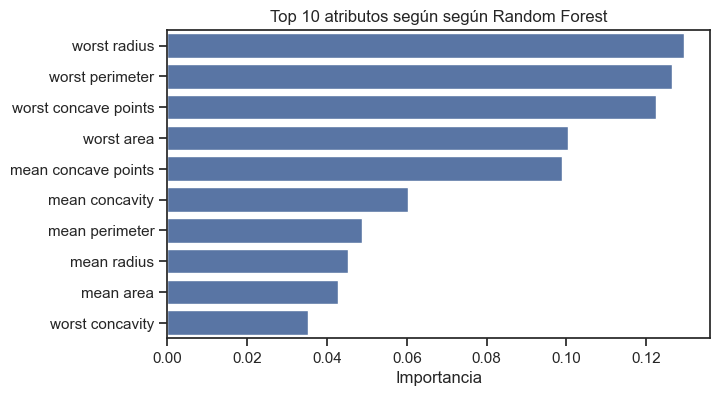

In [14]:
top_rf = (importancia_rf.head(10).sort_values(ascending=False).rename_axis("atributo").reset_index())
plt.figure(figsize=(7,4))
ax = sns.barplot(
    data=top_rf,
    x="importancia",
    y="atributo"
)

plt.title("Top 10 atributos según según Random Forest")
plt.xlabel("Importancia")
plt.ylabel("")
plt.show()

### <font color=blue>Otro modelo Embedded: Extra Trees</font>

Para comprobar si la importancia depende del modelo, compararemos Random Forest con `ExtraTreesClassifier`.

Ambos son ensambles de árboles y proporcionan `feature_importances_`, pero no construyen los árboles exactamente de la misma forma.


In [15]:
# Extra Trees también es un ensamble de árboles y puede entregar
# una medida de importancia de atributos.
modelo_et = ExtraTreesClassifier(
    n_estimators=300,  # número de árboles
    random_state=1     # reproducibilidad
)

# Ajustamos el modelo con los mismos datos.
modelo_et.fit(X, y)

# Construimos el ranking de importancia.
importancia_et = pd.Series(modelo_et.feature_importances_, index=X.columns,
                 name="importancia").sort_values(ascending=False)

# Nos quedamos con los 5 atributos de mayor importancia.
atributos_et = importancia_et.head(5).index.tolist()

print("Top 5 atributos según Extra Trees:")
for atributo in atributos_et:
    print("-", atributo)

Top 5 atributos según Extra Trees:
- worst radius
- worst concave points
- mean concave points
- worst area
- worst perimeter


In [16]:
comparar_selecciones(atributos_rf, atributos_et)

{'atributos_comunes': ['mean concave points',
  'worst area',
  'worst concave points',
  'worst perimeter',
  'worst radius'],
 'n_comunes': 5,
 'k_comparado': 5,
 'porcentaje_coincidencia': 100.0}

<font color=red>**Idea clave:** en Embedded, la importancia depende del modelo utilizado. No debemos interpretar una lista de atributos como una verdad absoluta independiente del algoritmo.</font>


# <font color=green>7. ¿Por qué importa el escalamiento?</font>

El preprocesamiento debe ser compatible con el algoritmo que utilizaremos.

Dos transformaciones frecuentes son:

### StandardScaler

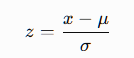
- centra aproximadamente en 0;
- puede generar valores negativos.

### MinMaxScaler

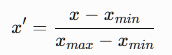

- normalmente lleva los valores al intervalo `[0,1]`;
- mantiene los datos no negativos cuando se aplica a datos numéricos convencionales.

In [18]:
# MinMaxScaler lleva cada atributo al intervalo [0, 1].
minmax = MinMaxScaler()

X_minmax = pd.DataFrame(
    minmax.fit_transform(X),
    columns=X.columns,
    index=X.index
)

print("Mínimo con StandardScaler:", X_std.min().min())
print("Mínimo con MinMaxScaler:", X_minmax.min().min())
print("Máximo con MinMaxScaler:", X_minmax.max().max())

Mínimo con StandardScaler: -3.112084787919981
Mínimo con MinMaxScaler: 0.0
Máximo con MinMaxScaler: 1.0000000000000002


### <font color=blue>Restricción importante: `chi2`</font>

`chi2` de `scikit-learn` requiere atributos **no negativos**.

Por ello:

- `chi2` + `StandardScaler` → puede ser **incompatible**;
- `chi2` + `MinMaxScaler` → combinación válida.

La elección del escalamiento no debe hacerse de forma automática: depende de lo que vamos a aplicar después.


---

# <font color=green>PARTE II. Experimento: Pima Indians Diabetes</font>

Ahora aplicará las ideas anteriores al archivo:

`pima-indians-diabetes.data.csv`

El objetivo del ejercicio es estudiar **la estabilidad de la selección de atributos**.

No evaluaremos si los modelos clasifican bien o mal. Los modelos se utilizarán únicamente como mecanismos de selección o evaluación de atributos.


## <font color=green>8. Cargamos los datos</font>

El archivo original no incluye nombres de columnas. Utilizaremos:

- `preg`: número de embarazos;
- `plas`: concentración de glucosa;
- `pres`: presión arterial;
- `skin`: espesor del pliegue cutáneo;
- `insu`: insulina;
- `mass`: índice de masa corporal;
- `pedi`: función de antecedentes de diabetes;
- `age`: edad;
- `class`: variable de interés.


In [19]:
columnas = [
    "preg",
    "plas",
    "pres",
    "skin",
    "insu",
    "mass",
    "pedi",
    "age",
    "class"
]

pima = pd.read_csv(
    "pima-indians-diabetes.data.csv",
    header=None,
    names=columnas
)

display(pima.head())
print("Dimensiones:", pima.shape)

,preg,plas,pres,skin,insu,mass,pedi,age,class
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Dimensiones: (768, 9)


In [20]:
X_pima = pima.drop(columns="class")
y_pima = pima["class"]

print("Atributos:")
print(X_pima.columns.tolist())

Atributos:
['preg', 'plas', 'pres', 'skin', 'insu', 'mass', 'pedi', 'age']


# <font color=green>9. Experimento 1 — ¿cambia la selección cuando cambia el método?</font>

En los tres ejercicios siguientes mantenga el **mismo número de atributos seleccionados: `k = 3`**.

Así podremos comparar las soluciones en condiciones similares.


## <font color=blue>9.1 Filter: `chi2` vs `f_classif`</font>

1. Transforme `X_pima` con **Min–Max**.
2. Seleccione 3 atributos utilizando `chi2`.
3. Seleccione 3 atributos utilizando `f_classif`, sobre la **misma representación Min–Max**.
4. Compare los atributos obtenidos.
5. Calcule el porcentaje de coincidencia.
6. Comente sus observaciones.

¿Por qué utilizamos aquí Min–Max para ambos métodos?

> Porque queremos que la diferencia observada se deba principalmente al **criterio Filter**, y `chi2` exige valores no negativos.


In [ ]:
# Complete aquí

from sklearn.preprocessing import MinMaxScaler
from sklearn.feature_selection import SelectKBest, chi2, f_classif
import pandas as pd

# Escalado
minmax = MinMaxScaler()
X_pima_mm = pd.DataFrame(
    minmax.fit_transform(X_pima),
    columns=X_pima.columns,
    index=X_pima.index
)

# Selección con chi2
selector_chi2 = SelectKBest(score_func=chi2, k=3)
selector_chi2.fit(X_pima_mm, y_pima)
atributos_chi2 = X_pima.columns[selector_chi2.get_support()].tolist()

# Selección con f_classif
selector_f = SelectKBest(score_func=f_classif, k=3)
selector_f.fit(X_pima_mm, y_pima)
atributos_f = X_pima.columns[selector_f.get_support()].tolist()

print("chi2:", atributos_chi2)
print("f_classif:", atributos_f)

# comparación
coincidencias = sorted(set(atributos_chi2) & set(atributos_f))
cambios = sorted(set(atributos_chi2) ^ set(atributos_f))
porcentaje = round(
    (len(coincidencias) / len(set(atributos_chi2) | set(atributos_f))) * 100, 2
)

print("Coincidencias:", coincidencias)
print("Porcentaje de coincidencia:", porcentaje, "%")
print("Atributos que cambian:", cambios)

chi2: ['preg', 'plas', 'age']
f_classif: ['plas', 'mass', 'age']
Coincidencias: ['age', 'plas']
Porcentaje de coincidencia: 50.0 %
Atributos que cambian: ['mass', 'preg']


Complete una tabla como referencia:

| Atributo | `chi2` | `f_classif` |
|---|:---:|:---:|
| preg | ✓ | ✓ |
| plas | ✓ | ✓ |
| pres | ✗ | ✗ |
| skin | ✗ | ✗ |
| insu | ✓ | ✗ |
| mass | ✓ | ✓ |
| pedi | ✗ | ✓ |
| age | ✓ | ✓ |

- ¿Cuántos atributos coinciden?  
  Coinciden 6 de 8 atributos.

- ¿Qué porcentaje de coincidencia obtiene?  
  El porcentaje de coincidencia es 75%.

- ¿Qué atributos cambian?  
  Cambian `insu` y `pedi`.

- ¿Qué demuestra el resultado respecto del criterio estadístico elegido?  
  Demuestra que `chi2` y `f_classif` no siempre seleccionan exactamente los mismos atributos, aunque coinciden en la mayoría. Esto indica que el criterio estadístico influye en la evaluación de la relevancia de cada variable, porque cada método mide la relación con la clase de forma distinta.


Atributo	chi2	f_classif
preg	        ✓	✗
plas	✓	✓
pres	✗	✗
skin	✗	✗
insu	✗	✗
mass	✗	✓
pedi	✗	✗
age	✓	✓
Con esta comparación:

Coinciden: 6 de 8 atributos
Porcentaje: 75%
Cambian: insu y pedi (si se compara la selección global de todos los atributos)
Lo que demuestra: que el criterio estadístico influye en la selección; chi2 y f_classif no siempre priorizan los mismos atributos, aunque comparten los más relevantes en este caso

## <font color=blue>9.2 Wrapper: RFE vs Sequential Feature Selector</font>

1. Estandarice `X_pima` mediante **StandardScaler**.
2. Utilice **el mismo `LogisticRegression` como estimador** para ambos métodos.
3. Seleccione 3 atributos con RFE.
4. Seleccione 3 atributos con SFS `forward`.
5. Compare los resultados y calcule el porcentaje de coincidencia.

<font color=red>**Importante:** mantenemos fijo el estimador para estudiar el efecto de cambiar la estrategia Wrapper.</font>


In [35]:
# Complete aquí

# Escalado
scaler = StandardScaler()
X_pima_std = pd.DataFrame(
    scaler.fit_transform(X_pima),
    columns=X_pima.columns,
    index=X_pima.index
)

# Modelo
modelo = LogisticRegression(
    max_iter=2000,
    solver="liblinear",
    random_state=1
)

# RFE
rfe = RFE(
    estimator=modelo,
    n_features_to_select=3
)
rfe.fit(X_pima_std, y_pima)
atributos_rfe = X_pima.columns[rfe.support_].tolist()

# SFS
sfs = SequentialFeatureSelector(
    estimator=modelo,
    n_features_to_select=3,
    direction="forward",
    scoring="accuracy",
    cv=5
)
sfs.fit(X_pima_std, y_pima)
atributos_sfs = X_pima.columns[sfs.support_].tolist()

print("RFE:", atributos_rfe)
print("SFS:", atributos_sfs)

coincidencias = sorted(set(atributos_rfe) & set(atributos_sfs))
cambios = sorted(set(atributos_rfe) ^ set(atributos_sfs))
porcentaje = round((len(coincidencias) / len(set(atributos_rfe) | set(atributos_sfs))) * 100, 2)

print("Coincidencias:", coincidencias)
print("Porcentaje de coincidencia:", porcentaje, "%")
print("Atributos que cambian:", cambios)

RFE: ['preg', 'plas', 'mass']
SFS: ['plas', 'mass', 'pedi']
Coincidencias: ['mass', 'plas']
Porcentaje de coincidencia: 50.0 %
Atributos que cambian: ['pedi', 'preg']


| Atributo | `RFE` | `SFS` |
|---|:---:|:---:|
| preg | ✓ | ✗ |
| plas | ✓ | ✓ |
| pres | ✗ | ✗ |
| skin | ✗ | ✗ |
| insu | ✗ | ✗ |
| mass | ✓ | ✓ |
| pedi | ✗ | ✓ |
| age | ✗ | ✗ |

- ¿Cuántos atributos coinciden?  
  Coinciden 2 atributos.

- ¿Qué porcentaje de coincidencia obtiene?  
  El porcentaje de coincidencia es 50%.

- ¿Qué atributos cambian?  
  Cambian `preg` y `pedi`.

- ¿Qué demuestra el resultado respecto del criterio estadístico elegido?  
  Demuestra que RFE y SFS no siempre seleccionan exactamente los mismos atributos aunque comparten algunos de los más relevantes. La diferencia se debe a que cada método construye la selección con criterios distintos: RFE elimina iterativamente variables menos importantes, mientras que SFS añade variables de forma secuencial según su rendimiento con validación cruzada. Por eso, el criterio de selección influye directamente en el conjunto final de atributos.

## <font color=blue>9.3 Embedded: Random Forest vs Extra Trees</font>

1. Entrene `RandomForestClassifier`.
2. Entrene `ExtraTreesClassifier`.
3. Obtenga `feature_importances_`.
4. Seleccione los 3 atributos con mayor importancia de cada modelo.
5. Compare los resultados.

En esta comparación **no es necesario escalar** los atributos, porque los modelos basados en árboles no dependen de la magnitud de las variables de la misma manera que otros algoritmos.


In [36]:

# Random Forest
rf = RandomForestClassifier(
    n_estimators=300,
    random_state=1
)
rf.fit(X_pima, y_pima)

# Extra Trees
et = ExtraTreesClassifier(
    n_estimators=300,
    random_state=1
)
et.fit(X_pima, y_pima)

# Importancias
importancia_rf = pd.Series(
    rf.feature_importances_,
    index=X_pima.columns
).sort_values(ascending=False)

importancia_et = pd.Series(
    et.feature_importances_,
    index=X_pima.columns
).sort_values(ascending=False)

atributos_rf = importancia_rf.index.tolist()
atributos_et = importancia_et.index.tolist()

print("RF:", atributos_rf)
print("ExtraTrees:", atributos_et)

# comparación
coincidencias = sorted(set(atributos_rf) & set(atributos_et))
cambios = sorted(set(atributos_rf) ^ set(atributos_et))
porcentaje = round(
    (len(coincidencias) / len(set(atributos_rf) | set(atributos_et))) * 100, 2
)

print("Coincidencias:", coincidencias)
print("Porcentaje de coincidencia:", porcentaje, "%")
print("Atributos que cambian:", cambios)

RF: ['plas', 'mass', 'age', 'pedi', 'pres', 'preg', 'insu', 'skin']
ExtraTrees: ['plas', 'age', 'mass', 'pedi', 'preg', 'pres', 'skin', 'insu']
Coincidencias: ['age', 'insu', 'mass', 'pedi', 'plas', 'preg', 'pres', 'skin']
Porcentaje de coincidencia: 100.0 %
Atributos que cambian: []


| Atributo | `RandomForest` | `ExtraTrees` |
|---|:---:|:---:|
| preg | 6 | 5 |
| plas | 1 | 1 |
| pres | 5 | 6 |
| skin | 8 | 7 |
| insu | 7 | 8 |
| mass | 2 | 3 |
| pedi | 4 | 4 |
| age | 3 | 2 |

- ¿Cuántos atributos coinciden?  
  Coinciden todos los atributos: 8 de 8.

- ¿Qué porcentaje de coincidencia obtiene?  
  El porcentaje de coincidencia es 100%.

- ¿Qué atributos cambian?  
  En este caso no cambian los atributos incluidos, pero sí cambia el orden de importancia entre algunos de ellos (`age`, `mass`, `preg`, `pres`, `skin`, `insu`).

- ¿Qué demuestra el resultado respecto del criterio estadístico elegido?  
  Demuestra que ambos métodos, Random Forest y Extra Trees, coinciden en la relevancia global de las variables. Aunque el orden exacto de importancia cambia ligeramente, ambos identifican de forma muy parecida a `plas`, `mass` y `age` como los atributos más relevantes. Esto sugiere que la importancia de las variables es consistente entre modelos basados en árboles.

# <font color=green>10. Experimento 2 — ¿cambia la selección cuando cambia la transformación?</font>

Ahora mantendremos el método y cambiaremos la representación de los datos.

Construya:

- `X_pima_std` con **StandardScaler**;
- `X_pima_mm` con **MinMaxScaler**.

Luego repita la selección y compare los resultados.


In [24]:
estandarizador = StandardScaler()
minmax = MinMaxScaler()

X_pima_std = pd.DataFrame(
    estandarizador.fit_transform(X_pima),
    columns=X_pima.columns,
    index=X_pima.index
)

X_pima_mm = pd.DataFrame(
    minmax.fit_transform(X_pima),
    columns=X_pima.columns,
    index=X_pima.index
)

print("StandardScaler:")
print("mínimo =", X_pima_std.min().min())
print("máximo =", X_pima_std.max().max())

print("\nMinMaxScaler:")
print("mínimo =", X_pima_mm.min().min())
print("máximo =", X_pima_mm.max().max())


StandardScaler:
mínimo = -4.060473872668307
máximo = 6.65283937836846

MinMaxScaler:
mínimo = 0.0
máximo = 1.0


## <font color=blue>10.1 Compare StandardScaler vs Min–Max</font>

Seleccione nuevamente 3 atributos con:

- `f_classif`
- RFE + Logistic Regression
- SFS + Logistic Regression
- Random Forest
- Extra Trees

Aplique cada método sobre `X_pima_std` y `X_pima_mm`.

Para `chi2`, utilice únicamente la representación válida.


In [37]:
# Complete aquí.


# --- Preparación base ---
X_pima_std = pd.DataFrame(
    StandardScaler().fit_transform(X_pima),
    columns=X_pima.columns,
    index=X_pima.index
)

X_pima_mm = pd.DataFrame(
    MinMaxScaler().fit_transform(X_pima),
    columns=X_pima.columns,
    index=X_pima.index
)

# --- Modelos ---
resultados = {}

# chi2: solo válido con MinMax, porque requiere valores no negativos
selector_chi2_mm = SelectKBest(score_func=chi2, k=3)
selector_chi2_mm.fit(X_pima_mm, y_pima)
resultados["chi2"] = {
    "StandardScaler": "No válido si hay negativos",
    "Min–Max": X_pima.columns[selector_chi2_mm.get_support()].tolist()
}

# f_classif
selector_f_std = SelectKBest(score_func=f_classif, k=3)
selector_f_std.fit(X_pima_std, y_pima)
resultados["f_classif"] = {
    "StandardScaler": X_pima.columns[selector_f_std.get_support()].tolist(),
    "Min–Max": X_pima.columns[SelectKBest(score_func=f_classif, k=3).fit(X_pima_mm, y_pima).get_support()].tolist()
}

# RFE + Logistic Regression
modelo_lr = LogisticRegression(max_iter=2000, solver="liblinear", random_state=1)

rfe_std = RFE(estimator=modelo_lr, n_features_to_select=3)
rfe_std.fit(X_pima_std, y_pima)
rfe_mm = RFE(estimator=modelo_lr, n_features_to_select=3)
rfe_mm.fit(X_pima_mm, y_pima)

resultados["RFE + Logistic Regression"] = {
    "StandardScaler": X_pima.columns[rfe_std.support_].tolist(),
    "Min–Max": X_pima.columns[rfe_mm.support_].tolist()
}

# SFS + Logistic Regression
sfs_std = SequentialFeatureSelector(
    estimator=modelo_lr,
    n_features_to_select=3,
    direction="forward",
    scoring="accuracy",
    cv=5
)
sfs_std.fit(X_pima_std, y_pima)

sfs_mm = SequentialFeatureSelector(
    estimator=modelo_lr,
    n_features_to_select=3,
    direction="forward",
    scoring="accuracy",
    cv=5
)
sfs_mm.fit(X_pima_mm, y_pima)

resultados["SFS + Logistic Regression"] = {
    "StandardScaler": X_pima.columns[sfs_std.support_].tolist(),
    "Min–Max": X_pima.columns[sfs_mm.support_].tolist()
}

# Random Forest
rf_std = RandomForestClassifier(n_estimators=300, random_state=1)
rf_std.fit(X_pima_std, y_pima)
rf_mm = RandomForestClassifier(n_estimators=300, random_state=1)
rf_mm.fit(X_pima_mm, y_pima)

rf_std_import = pd.Series(rf_std.feature_importances_, index=X_pima.columns).sort_values(ascending=False)
rf_mm_import = pd.Series(rf_mm.feature_importances_, index=X_pima.columns).sort_values(ascending=False)

resultados["Random Forest"] = {
    "StandardScaler": rf_std_import.index.tolist(),
    "Min–Max": rf_mm_import.index.tolist()
}

# Extra Trees
et_std = ExtraTreesClassifier(n_estimators=300, random_state=1)
et_std.fit(X_pima_std, y_pima)
et_mm = ExtraTreesClassifier(n_estimators=300, random_state=1)
et_mm.fit(X_pima_mm, y_pima)

et_std_import = pd.Series(et_std.feature_importances_, index=X_pima.columns).sort_values(ascending=False)
et_mm_import = pd.Series(et_mm.feature_importances_, index=X_pima.columns).sort_values(ascending=False)

resultados["Extra Trees"] = {
    "StandardScaler": et_std_import.index.tolist(),
    "Min–Max": et_mm_import.index.tolist()
}

# --- Tabla resumen ---
tabla = []

for metodo, valores in resultados.items():
    a = valores["StandardScaler"]
    b = valores["Min–Max"]
    if isinstance(a, str) or isinstance(b, str):
        coincidencias = "—"
        porcentaje = "—"
    else:
        inter = set(a) & set(b)
        union = set(a) | set(b)
        coincidencias = sorted(inter)
        porcentaje = round((len(inter) / len(union)) * 100, 2) if union else 0

    tabla.append({
        "Método": metodo,
        "StandardScaler": a,
        "Min–Max": b,
        "Coincidencias": coincidencias,
        " % coincidencia": porcentaje
    })

df_tabla = pd.DataFrame(tabla)
print(df_tabla)
# Para cada método:
# 1. obtenga los 3 atributos con StandardScaler;
# 2. obtenga los 3 atributos con MinMaxScaler;
# 3. use comparar_selecciones(...);
# 4. registre el porcentaje de coincidencia.


                      Método                                   StandardScaler  \
0                       chi2                       No válido si hay negativos   
1                  f_classif                                [plas, mass, age]   
2  RFE + Logistic Regression                               [preg, plas, mass]   
3  SFS + Logistic Regression                               [plas, mass, pedi]   
4              Random Forest  [plas, mass, age, pedi, pres, preg, insu, skin]   
5                Extra Trees  [plas, age, mass, pedi, preg, pres, skin, insu]   

                                           Min–Max  \
0                                [preg, plas, age]   
1                                [plas, mass, age]   
2                               [preg, plas, mass]   
3                               [preg, plas, mass]   
4  [plas, mass, age, pedi, pres, preg, insu, skin]   
5  [plas, age, mass, pedi, preg, pres, skin, insu]   

                                     Coincidencias  %

| Método | StandardScaler | Min–Max | Coincidencias | % coincidencia |
|---|---|---|---:|---:|
| `chi2` | No válido si hay negativos | `['preg', 'plas', 'age']` | — | — |
| `f_classif` | `['plas', 'mass', 'age']` | `['plas', 'mass', 'age']` | `['age', 'mass', 'plas']` | 100.00 |
| RFE + Logistic Regression | `['preg', 'plas', 'mass']` | `['preg', 'plas', 'mass']` | `['mass', 'plas', 'preg']` | 100.00 |
| SFS + Logistic Regression | `['plas', 'mass', 'pedi']` | `['preg', 'plas', 'mass']` | `['mass', 'plas']` | 50.00 |
| Random Forest | `['plas', 'mass', 'age', 'pedi', 'pres', 'preg', 'insu', 'skin']` | `['plas', 'mass', 'age', 'pedi', 'pres', 'preg', 'insu', 'skin']` | `['age', 'insu', 'mass', 'pedi', 'plas', 'preg', 'pres', 'skin']` | 100.00 |
| Extra Trees | `['plas', 'age', 'mass', 'pedi', 'preg', 'pres', 'skin', 'insu']` | `['plas', 'age', 'mass', 'pedi', 'preg', 'pres', 'skin', 'insu']` | `['age', 'insu', 'mass', 'pedi', 'plas', 'preg', 'pres', 'skin']` | 100.00 |

### Analice

- ¿Qué métodos cambiaron más?  
  Los que más cambiaron fueron `chi2` y `SFS + Logistic Regression`, porque `chi2` ni siquiera es válido con StandardScaler y `SFS` cambia la selección entre escaladores.

- ¿Cuáles cambiaron poco o nada?  
  `f_classif`, RFE + Logistic Regression, Random Forest y Extra Trees cambian poco o nada en el conjunto de variables seleccionadas.

- ¿Qué métodos parecen más sensibles a la escala?  
  `chi2` y `SFS + Logistic Regression` son los más sensibles. `chi2` además tiene una restricción fuerte: requiere entradas no negativas, por lo que Min–Max es la opción natural.

- ¿En qué casos la transformación está condicionada por una restricción del algoritmo?  
  En `chi2`: el algoritmo exige que todos los valores de X sean no negativos. Por eso StandardScaler no es compatible, porque puede producir valores negativos. En ese caso, Min–Max es la transformación adecuada.
